In [5]:
from dataset import df
import pandas as pd

# soil_type, bedrock, rock_fragments, depth, landcover

df

,sand,elcosp,slope,landcover,orgc,inorgc,silt_clay,phaq,bedrock,soil_type,ecoregion,rock_fragments,depth
0,53.411810,0.117950,0.153699,10.0,15.868971,0.000000,46.588190,5.917957,rocas_metamorficas,FLUVISOL EUTRICO,1.0,0.001939,0_5
1,33.299825,0.049220,0.153699,10.0,8.683302,0.000000,66.700175,5.854219,rocas_metamorficas,FLUVISOL EUTRICO,1.0,0.011414,15_30
2,48.878541,0.102914,0.153699,10.0,14.303404,0.000000,51.121459,5.902915,rocas_metamorficas,FLUVISOL EUTRICO,1.0,0.000931,5_15
3,83.328428,0.112064,0.153699,17.0,10.530031,0.000000,16.671572,5.824141,rocas_metamorficas,REGOSOL EUTRICO,7.0,0.001939,0_5
4,88.791135,0.018339,0.153699,17.0,6.114025,0.000000,11.208865,6.449995,rocas_metamorficas,REGOSOL EUTRICO,7.0,0.011414,15_30
...,...,...,...,...,...,...,...,...,...,...,...,...,...
10044,68.286592,0.113175,0.912038,12.0,1.612308,163.076087,31.713408,8.675840,rocas_sedimentarias,REGOSOL CALCARICO,5.0,7.833180,15_30
10045,67.685121,0.085524,0.912038,12.0,2.425957,163.076087,32.314879,8.726544,rocas_sedimentarias,REGOSOL CALCARICO,5.0,6.071739,5_15
10049,59.221832,0.217659,2.340468,7.0,18.357349,0.000000,40.778168,6.280829,rocas_sedimentarias,VERTISOL CROMICO,5.0,20.874676,0_5
10050,60.271647,0.093543,2.340468,7.0,14.050194,63.348584,39.728353,5.635044,rocas_sedimentarias,VERTISOL CROMICO,5.0,23.411763,15_30


## Correlation matrix

Encoded soil_type: {'ACRISOL HUMICO': 0, 'ACRISOL ORTICO': 1, 'ANDOSOL HUMICO': 2, 'ANDOSOL MOLICO': 3, 'ANDOSOL OCRICO': 4, 'ARENOSOL CAMBICO': 5, 'CAMBISOL CALCICO (calcarico)': 6, 'CAMBISOL CROMICO': 7, 'CAMBISOL DISTRICO': 8, 'CAMBISOL EUTRICO': 9, 'CAMBISOL FERRALICO': 10, 'CAMBISOL GLEYICO': 11, 'CAMBISOL HUMICO': 12, 'CAMBISOL VERTICO': 13, 'CASTAÑOSEM  HAPLICO': 14, 'CASTAÑOZEM CALCICO': 15, 'CASTAÑOZEM LUVICO': 16, 'FEOZEM CALCARICO': 17, 'FEOZEM HAPLICO': 18, 'FEOZEM LUVICO': 19, 'FLUVISOL CALCARICO': 20, 'FLUVISOL DISTRICO': 21, 'FLUVISOL EUTRICO': 22, 'FLUVISOL GLEYICO': 23, 'GLEYSOL EUTRICO': 24, 'GLEYSOL HUMICO': 25, 'GLEYSOL MOLICO': 26, 'GLEYSOL PLINTICO': 27, 'GLEYSOL VERTICO': 28, 'HISTOSOL EUTRICO': 29, 'LITOSOL': 30, 'LUVISOL CROMICO': 31, 'LUVISOL FERRICO': 32, 'LUVISOL ORTICO': 33, 'LUVISOL PLINTICO': 34, 'LUVISOL VERTICO': 35, 'NITOSOL DISTRICO': 36, 'NITOSOL EUTRICO': 37, 'PLANOSOL EUTRICO': 38, 'PLANOSOL MOLICO': 39, 'PLANOSOL SOLODICO': 40, 'REGOSOL CALCARICO'

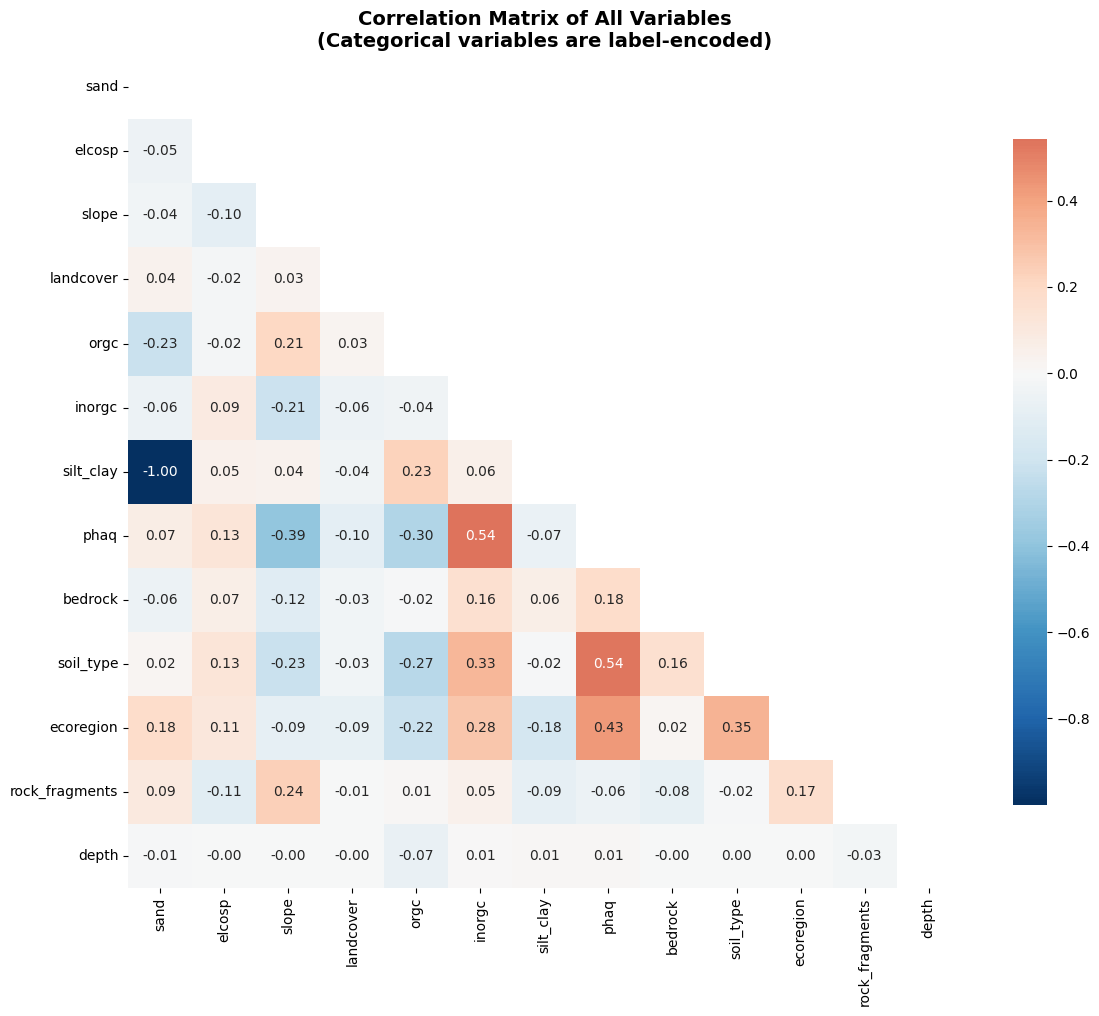

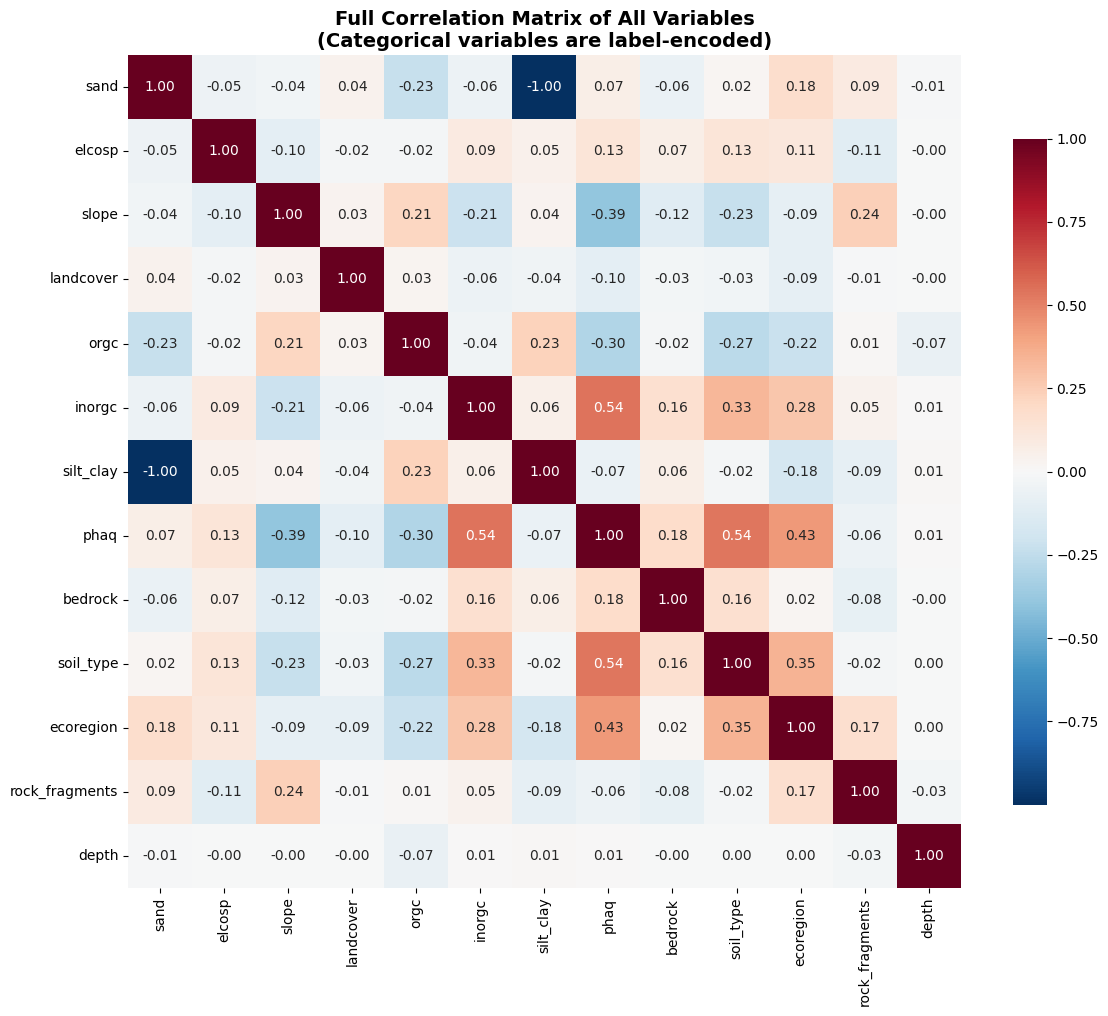


Correlation Matrix:
                 sand  elcosp  slope  landcover   orgc  inorgc  silt_clay  \
sand            1.000  -0.053 -0.038      0.042 -0.227  -0.059     -1.000   
elcosp         -0.053   1.000 -0.098     -0.020 -0.018   0.090      0.053   
slope          -0.038  -0.098  1.000      0.034  0.212  -0.214      0.038   
landcover       0.042  -0.020  0.034      1.000  0.028  -0.056     -0.042   
orgc           -0.227  -0.018  0.212      0.028  1.000  -0.044      0.227   
inorgc         -0.059   0.090 -0.214     -0.056 -0.044   1.000      0.059   
silt_clay      -1.000   0.053  0.038     -0.042  0.227   0.059      1.000   
phaq            0.068   0.132 -0.395     -0.096 -0.304   0.544     -0.068   
bedrock        -0.063   0.065 -0.120     -0.029 -0.016   0.164      0.063   
soil_type       0.016   0.130 -0.227     -0.034 -0.271   0.331     -0.016   
ecoregion       0.179   0.114 -0.094     -0.089 -0.223   0.278     -0.179   
rock_fragments  0.092  -0.110  0.237     -0.008  0.009 

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

# Create a copy of the dataframe to avoid modifying the original
df_encoded = df.copy()

# Define categorical columns
categorical_columns = ['soil_type', 'bedrock', 'rock_fragments', 'depth', 'landcover']

# Label encode categorical variables
label_encoders = {}
for col in categorical_columns:
    if col in df_encoded.columns:
        le = LabelEncoder()
        df_encoded[col] = le.fit_transform(df_encoded[col].astype(str))
        label_encoders[col] = le
        print(f"Encoded {col}: {dict(zip(le.classes_, le.transform(le.classes_)))}")

# Calculate correlation matrix
correlation_matrix = df_encoded.corr()

# Create the correlation matrix plot
plt.figure(figsize=(12, 10))
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))  # Mask upper triangle
sns.heatmap(correlation_matrix, 
            annot=True,                    # Show correlation values
            cmap='RdBu_r',                 # Red-Blue color scheme (reversed)
            center=0,                      # Center colormap at 0
            square=True,                   # Square aspect ratio
            fmt='.2f',                     # Format to 2 decimal places
            cbar_kws={'shrink': 0.8},      # Colorbar size
            mask=mask)                     # Only show lower triangle

plt.title('Correlation Matrix of All Variables\n(Categorical variables are label-encoded)', 
          fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Alternative: Full correlation matrix (without masking)
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, 
            annot=True,
            cmap='RdBu_r',
            center=0,
            square=True,
            fmt='.2f',
            cbar_kws={'shrink': 0.8})

plt.title('Full Correlation Matrix of All Variables\n(Categorical variables are label-encoded)', 
          fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Print correlation matrix as dataframe for easier reading
print("\nCorrelation Matrix:")
print(correlation_matrix.round(3))

# Find strongest correlations (excluding self-correlations)
def find_strong_correlations(corr_matrix, threshold=0.5):
    """Find correlations above the threshold"""
    strong_corr = []
    for i in range(len(corr_matrix.columns)):
        for j in range(i+1, len(corr_matrix.columns)):
            corr_val = corr_matrix.iloc[i, j]
            if abs(corr_val) >= threshold:
                strong_corr.append({
                    'Variable 1': corr_matrix.columns[i],
                    'Variable 2': corr_matrix.columns[j],
                    'Correlation': corr_val
                })
    return pd.DataFrame(strong_corr).sort_values('Correlation', key=abs, ascending=False)

# Display strong correlations
print(f"\nStrong correlations (|r| >= 0.5):")
strong_corr_df = find_strong_correlations(correlation_matrix, 0.5)
if not strong_corr_df.empty:
    print(strong_corr_df.to_string(index=False))
else:
    print("No correlations found above threshold of 0.5")

In [7]:
import pandas as pd
import numpy as np
from pgmpy.models import BayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination
from pgmpy.estimators import MaximumLikelihoodEstimator, BayesianEstimator
import networkx as nx
import matplotlib.pyplot as plt
from collections import defaultdict
import warnings
warnings.filterwarnings('ignore')

class SoilBayesianNetwork:
    def __init__(self, edges, categorical_vars=None):
        """
        Initialize the Soil Bayesian Network
        
        Parameters:
        - edges: List of tuples representing causal relationships
        - categorical_vars: List of categorical variable names
        """
        self.edges = edges
        self.categorical_vars = categorical_vars or []
        self.model = None
        self.inference = None
        self.discretized_data = None
        self.discretization_info = {}
        
    def discretize_continuous_variables(self, df, n_bins=3):
        """
        Discretize continuous variables into bins (low, medium, high)
        """
        df_discretized = df.copy()
        
        # Get all variables from edges
        all_vars = set()
        for edge in self.edges:
            all_vars.add(edge[0])
            all_vars.add(edge[1])
        
        # Identify numerical variables
        numerical_vars = [var for var in all_vars if var not in self.categorical_vars and var in df.columns]
        
        for var in numerical_vars:
            if var in df.columns:
                # Create bins with equal frequency (quantile-based binning)
                try:
                    df_discretized[var], bins = pd.qcut(df[var], 
                                                      q=n_bins, 
                                                      labels=['low', 'medium', 'high'],
                                                      duplicates='drop',
                                                      retbins=True)
                    
                    # Store discretization info for interpretation
                    self.discretization_info[var] = {
                        'bins': bins,
                        'labels': ['low', 'medium', 'high'][:len(bins)-1]
                    }
                except Exception as e:
                    # Fallback to value-based binning if quantile fails
                    df_discretized[var], bins = pd.cut(df[var], 
                                                      bins=n_bins, 
                                                      labels=['low', 'medium', 'high'][:n_bins],
                                                      retbins=True)
                    self.discretization_info[var] = {
                        'bins': bins,
                        'labels': ['low', 'medium', 'high'][:n_bins]
                    }
        
        self.discretized_data = df_discretized
        return df_discretized
    
    def build_network(self, df):
        """
        Build and fit the Bayesian Network
        """
        # Discretize continuous variables
        df_processed = self.discretize_continuous_variables(df)
        
        # Create the Bayesian Network structure
        self.model = BayesianNetwork(self.edges)
        
        # Fit the model using Maximum Likelihood Estimation
        self.model.fit(df_processed, estimator=MaximumLikelihoodEstimator)
        
        # Create inference object
        self.inference = VariableElimination(self.model)
        
        print("Bayesian Network built successfully!")
        print(f"Nodes: {self.model.nodes()}")
        print(f"Edges: {self.model.edges()}")
        
    def query_conditional_probability(self, evidence, query_vars=None):
        """
        Perform conditional probability queries
        
        Parameters:
        - evidence: Dictionary of evidence variables and their states
        - query_vars: List of variables to query (if None, queries all other variables)
        
        Returns:
        - Dictionary of probability distributions
        """
        if not self.inference:
            raise ValueError("Network not built yet. Call build_network() first.")
        
        if query_vars is None:
            # Query all variables except those in evidence
            query_vars = [var for var in self.model.nodes() if var not in evidence.keys()]
        
        results = {}
        
        for var in query_vars:
            try:
                result = self.inference.query(variables=[var], evidence=evidence)
                results[var] = result
            except Exception as e:
                print(f"Could not query {var}: {str(e)}")
        
        return results
    
    def interpret_results(self, results, top_n=None):
        """
        Interpret and display query results in a readable format
        """
        interpretation = {}
        
        for var, result in results.items():
            var_results = {}
            
            # Get probabilities for each state
            for i, state in enumerate(result.variables):
                if state == var:
                    for j, state_value in enumerate(result.state_names[state]):
                        prob = result.values.flatten()[j]
                        var_results[state_value] = prob
            
            # Sort by probability if requested
            if top_n:
                var_results = dict(sorted(var_results.items(), 
                                        key=lambda x: x[1], 
                                        reverse=True)[:top_n])
            
            interpretation[var] = var_results
        
        return interpretation
    
    def print_conditional_analysis(self, evidence, query_vars=None, top_n=None):
        """
        Print a formatted conditional probability analysis
        """
        print(f"\n=== Conditional Probability Analysis ===")
        print(f"Given evidence: {evidence}")
        print("="*50)
        
        results = self.query_conditional_probability(evidence, query_vars)
        interpretation = self.interpret_results(results, top_n)
        
        for var, probs in interpretation.items():
            print(f"\n{var.upper()}:")
            for state, prob in probs.items():
                # Add discretization info for continuous variables
                if var in self.discretization_info:
                    bins = self.discretization_info[var]['bins']
                    if state == 'low':
                        range_info = f" (≤ {bins[1]:.3f})"
                    elif state == 'medium' and len(bins) > 2:
                        range_info = f" ({bins[1]:.3f} - {bins[2]:.3f})"
                    elif state == 'high':
                        range_info = f" (≥ {bins[-2]:.3f})"
                    else:
                        range_info = ""
                else:
                    range_info = ""
                
                print(f"  {state}{range_info}: {prob:.3f} ({prob*100:.1f}%)")
    
    def get_variable_info(self):
        """
        Get information about variables and their discretization
        """
        print("\n=== Variable Information ===")
        print("Categorical variables:", self.categorical_vars)
        print("\nNumerical variables (discretized):")
        for var, info in self.discretization_info.items():
            bins = info['bins']
            print(f"  {var}:")
            print(f"    Low: ≤ {bins[1]:.3f}")
            if len(bins) > 2:
                print(f"    Medium: {bins[1]:.3f} - {bins[2]:.3f}")
            print(f"    High: ≥ {bins[-2]:.3f}")
    
    def visualize_network(self, figsize=(12, 8)):
        """
        Visualize the network structure
        """
        plt.figure(figsize=figsize)
        
        # Create networkx graph for visualization
        G = nx.DiGraph()
        G.add_edges_from(self.edges)
        
        # Use hierarchical layout
        pos = nx.spring_layout(G, k=2, iterations=50)
        
        # Draw the network
        nx.draw(G, pos, with_labels=True, node_color='lightblue', 
                node_size=3000, font_size=10, font_weight='bold',
                arrows=True, arrowsize=20, edge_color='gray')
        
        plt.title("Soil Variables Causal Network")
        plt.axis('off')
        plt.tight_layout()
        plt.show()

Bayesian Network built successfully!
Nodes: ['sand', 'elcosp', 'slope', 'landcover', 'orgc', 'inorgc', 'silt_clay', 'phaq', 'bedrock', 'soil_type', 'ecoregion', 'rock_fragments', 'depth']
Edges: [('sand', 'elcosp'), ('elcosp', 'inorgc'), ('slope', 'landcover'), ('slope', 'orgc'), ('slope', 'inorgc'), ('landcover', 'elcosp'), ('landcover', 'orgc'), ('silt_clay', 'elcosp'), ('silt_clay', 'phaq'), ('phaq', 'elcosp'), ('phaq', 'orgc'), ('phaq', 'inorgc'), ('bedrock', 'soil_type'), ('soil_type', 'silt_clay'), ('soil_type', 'phaq'), ('soil_type', 'elcosp'), ('ecoregion', 'landcover'), ('ecoregion', 'orgc'), ('ecoregion', 'phaq'), ('ecoregion', 'inorgc'), ('rock_fragments', 'orgc'), ('rock_fragments', 'inorgc'), ('depth', 'rock_fragments'), ('depth', 'orgc'), ('depth', 'inorgc')]

=== Variable Information ===
Categorical variables: ['soil_type', 'bedrock', 'rock_fragments', 'depth', 'landcover', 'ecoregion']

Numerical variables (discretized):
  silt_clay:
    Low: ≤ 38.236
    Medium: 38.236

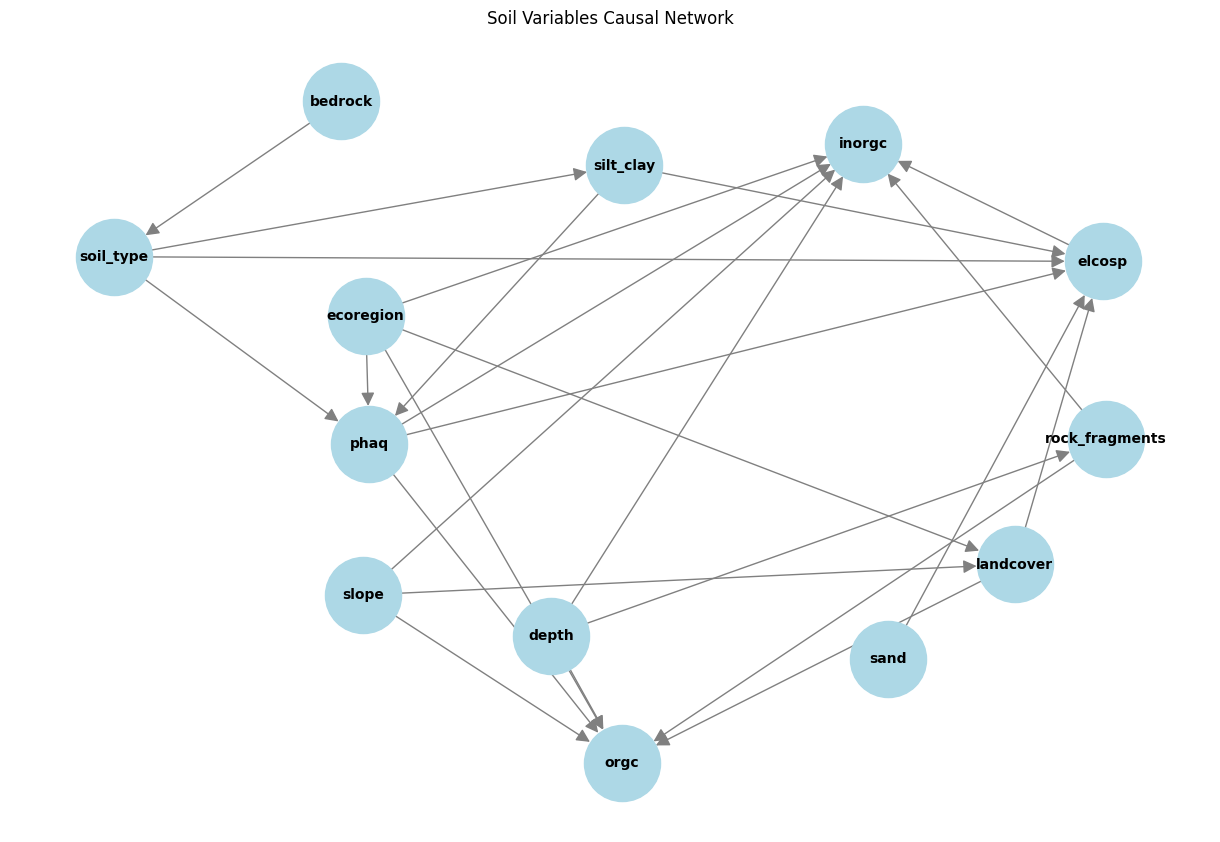

In [8]:
"""
Example of how to use the SoilBayesianNetwork class
"""

# Define your edges (from your provided data)
edges = [
    ('sand', 'elcosp'),
    ('slope', 'landcover'), ('slope', 'orgc'), ('slope', 'inorgc'),
    ('silt_clay', 'elcosp'), ('silt_clay', 'phaq'),
    ('bedrock', 'soil_type'),
    ('soil_type', 'silt_clay'), ('soil_type', 'phaq'), ('soil_type', 'elcosp'),
    ('elcosp', 'inorgc'),
    ('landcover', 'elcosp'), ('landcover', 'orgc'),
    ('phaq', 'elcosp'), ('phaq', 'orgc'), ('phaq', 'inorgc'),
    ('ecoregion', 'landcover'), ('ecoregion', 'orgc'), ('ecoregion', 'phaq'), ('ecoregion', 'inorgc'),
    ('rock_fragments', 'orgc'), ('rock_fragments', 'inorgc'),
    ('depth', 'rock_fragments'), ('depth', 'orgc'), ('depth', 'inorgc')
]

# Define categorical variables
categorical_vars = ['soil_type', 'bedrock', 'rock_fragments', 'depth', 'landcover', 'ecoregion']

# Initialize the network
soil_bn = SoilBayesianNetwork(edges, categorical_vars)

# Assuming you have your dataframe 'df'
soil_bn.build_network(df)

# Get variable information
soil_bn.get_variable_info()

# Example queries:
# 1. When orgc is high, what happens to other variables?
soil_bn.print_conditional_analysis({'orgc': 'high'})

# 2. When both orgc is high and slope is low?
# soil_bn.print_conditional_analysis({'orgc': 'high', 'slope': 'low'})

# 3. Query specific variables only
# soil_bn.print_conditional_analysis({'orgc': 'high'}, 
#                                   query_vars=['inorgc', 'phaq', 'elcosp'])

# Visualize the network
soil_bn.visualize_network()

In [9]:
import pandas as pd
import numpy as np
from pgmpy.models import BayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination
from pgmpy.estimators import MaximumLikelihoodEstimator, BayesianEstimator
import networkx as nx
import matplotlib.pyplot as plt
from collections import defaultdict
import warnings
warnings.filterwarnings('ignore')

class SoilBayesianNetwork:
    def __init__(self, edges, categorical_vars=None):
        """
        Initialize the Soil Bayesian Network
        
        Parameters:
        - edges: List of tuples representing causal relationships
        - categorical_vars: List of categorical variable names
        """
        self.edges = edges
        self.categorical_vars = categorical_vars or []
        self.model = None
        self.inference = None
        self.discretized_data = None
        self.discretization_info = {}
        
    def discretize_continuous_variables(self, df, n_bins=3, custom_bins=None):
        """
        Discretize continuous variables into bins (low, medium, high)
        
        Parameters:
        - df: DataFrame to discretize
        - n_bins: Default number of bins for automatic discretization
        - custom_bins: Dictionary of custom bin definitions for specific variables
                      Format: {'var_name': {'bins': [cutpoints], 'labels': ['low', 'medium', 'high']}}
        """
        df_discretized = df.copy()
        
        # Default custom bins with sand specification
        if custom_bins is None:
            custom_bins = {}
        
        # Add sand custom discretization
        if 'sand' not in custom_bins:
            custom_bins['sand'] = {
                'bins': [0, 20, 45, float('inf')],
                'labels': ['low', 'medium', 'high']
            }
        
        # Get all variables from edges
        all_vars = set()
        for edge in self.edges:
            all_vars.add(edge[0])
            all_vars.add(edge[1])
        
        # Identify numerical variables
        numerical_vars = [var for var in all_vars if var not in self.categorical_vars and var in df.columns]
        
        for var in numerical_vars:
            if var in df.columns:
                # Check if custom bins are specified for this variable
                if var in custom_bins:
                    bins = custom_bins[var]['bins']
                    labels = custom_bins[var]['labels']
                    
                    # Use custom bins
                    df_discretized[var] = pd.cut(df[var], 
                                               bins=bins, 
                                               labels=labels,
                                               include_lowest=True,
                                               right=False)
                    
                    # Store discretization info for interpretation
                    self.discretization_info[var] = {
                        'bins': bins,
                        'labels': labels,
                        'custom': True
                    }
                else:
                    # Use automatic discretization
                    try:
                        df_discretized[var], bins = pd.qcut(df[var], 
                                                          q=n_bins, 
                                                          labels=['low', 'medium', 'high'],
                                                          duplicates='drop',
                                                          retbins=True)
                        
                        # Store discretization info for interpretation
                        self.discretization_info[var] = {
                            'bins': bins,
                            'labels': ['low', 'medium', 'high'][:len(bins)-1],
                            'custom': False
                        }
                    except Exception as e:
                        # Fallback to value-based binning if quantile fails
                        df_discretized[var], bins = pd.cut(df[var], 
                                                          bins=n_bins, 
                                                          labels=['low', 'medium', 'high'][:n_bins],
                                                          retbins=True)
                        self.discretization_info[var] = {
                            'bins': bins,
                            'labels': ['low', 'medium', 'high'][:n_bins],
                            'custom': False
                        }
        
        self.discretized_data = df_discretized
        return df_discretized
    
    def build_network(self, df, custom_bins=None):
        """
        Build and fit the Bayesian Network
        
        Parameters:
        - df: DataFrame with soil data
        - custom_bins: Dictionary of custom bin definitions for specific variables
        """
        # Discretize continuous variables
        df_processed = self.discretize_continuous_variables(df, custom_bins=custom_bins)
        
        # Create the Bayesian Network structure
        self.model = BayesianNetwork(self.edges)
        
        # Fit the model using Maximum Likelihood Estimation
        self.model.fit(df_processed, estimator=MaximumLikelihoodEstimator)
        
        # Create inference object
        self.inference = VariableElimination(self.model)
        
        print("Bayesian Network built successfully!")
        print(f"Nodes: {self.model.nodes()}")
        print(f"Edges: {self.model.edges()}")
        
        # Show sand discretization info
        if 'sand' in self.discretization_info:
            print(f"\nSand discretization:")
            print(f"  Low: ≤ 20")
            print(f"  Medium: 21-45")
            print(f"  High: > 45")
        
    def query_conditional_probability(self, evidence, query_vars=None):
        """
        Perform conditional probability queries
        
        Parameters:
        - evidence: Dictionary of evidence variables and their states
        - query_vars: List of variables to query (if None, queries all other variables)
        
        Returns:
        - Dictionary of probability distributions
        """
        if not self.inference:
            raise ValueError("Network not built yet. Call build_network() first.")
        
        if query_vars is None:
            # Query all variables except those in evidence
            query_vars = [var for var in self.model.nodes() if var not in evidence.keys()]
        
        results = {}
        
        for var in query_vars:
            try:
                result = self.inference.query(variables=[var], evidence=evidence)
                results[var] = result
            except Exception as e:
                print(f"Could not query {var}: {str(e)}")
        
        return results
    
    def interpret_results(self, results, top_n=None):
        """
        Interpret and display query results in a readable format
        """
        interpretation = {}
        
        for var, result in results.items():
            var_results = {}
            
            # Get probabilities for each state
            for i, state in enumerate(result.variables):
                if state == var:
                    for j, state_value in enumerate(result.state_names[state]):
                        prob = result.values.flatten()[j]
                        var_results[state_value] = prob
            
            # Sort by probability if requested
            if top_n:
                var_results = dict(sorted(var_results.items(), 
                                        key=lambda x: x[1], 
                                        reverse=True)[:top_n])
            
            interpretation[var] = var_results
        
        return interpretation
    
    def print_conditional_analysis(self, evidence, query_vars=None, top_n=None):
        """
        Print a formatted conditional probability analysis
        """
        print(f"\n=== Conditional Probability Analysis ===")
        print(f"Given evidence: {evidence}")
        print("="*50)
        
        results = self.query_conditional_probability(evidence, query_vars)
        interpretation = self.interpret_results(results, top_n)
        
        for var, probs in interpretation.items():
            print(f"\n{var.upper()}:")
            for state, prob in probs.items():
                # Add discretization info for continuous variables
                if var in self.discretization_info:
                    info = self.discretization_info[var]
                    if info.get('custom', False):
                        # Custom bins - use specific ranges
                        if var == 'sand':
                            if state == 'low':
                                range_info = f" (≤ 20)"
                            elif state == 'medium':
                                range_info = f" (21-45)"
                            elif state == 'high':
                                range_info = f" (> 45)"
                            else:
                                range_info = ""
                        else:
                            # For other custom variables, use general format
                            bins = info['bins']
                            if state == 'low':
                                range_info = f" (≤ {bins[1]})"
                            elif state == 'medium' and len(bins) > 2:
                                range_info = f" ({bins[1]}-{bins[2]})"
                            elif state == 'high':
                                range_info = f" (> {bins[-2]})"
                            else:
                                range_info = ""
                    else:
                        # Automatic bins
                        bins = info['bins']
                        if state == 'low':
                            range_info = f" (≤ {bins[1]:.3f})"
                        elif state == 'medium' and len(bins) > 2:
                            range_info = f" ({bins[1]:.3f} - {bins[2]:.3f})"
                        elif state == 'high':
                            range_info = f" (≥ {bins[-2]:.3f})"
                        else:
                            range_info = ""
                else:
                    range_info = ""
                
                print(f"  {state}{range_info}: {prob:.3f} ({prob*100:.1f}%)")
    
    def get_variable_info(self):
        """
        Get information about variables and their discretization
        """
        print("\n=== Variable Information ===")
        print("Categorical variables:", self.categorical_vars)
        print("\nNumerical variables (discretized):")
        for var, info in self.discretization_info.items():
            print(f"  {var}:")
            if info.get('custom', False):
                # Custom discretization
                if var == 'sand':
                    print(f"    Low: ≤ 20")
                    print(f"    Medium: 21-45")
                    print(f"    High: > 45")
                else:
                    bins = info['bins']
                    labels = info['labels']
                    for i, label in enumerate(labels):
                        if i == 0:
                            print(f"    {label.title()}: ≤ {bins[i+1]}")
                        elif i == len(labels) - 1:
                            print(f"    {label.title()}: > {bins[i]}")
                        else:
                            print(f"    {label.title()}: {bins[i]}-{bins[i+1]}")
            else:
                # Automatic discretization
                bins = info['bins']
                print(f"    Low: ≤ {bins[1]:.3f}")
                if len(bins) > 2:
                    print(f"    Medium: {bins[1]:.3f} - {bins[2]:.3f}")
                print(f"    High: ≥ {bins[-2]:.3f}")
    
    def visualize_network(self, figsize=(12, 8)):
        """
        Visualize the network structure
        """
        plt.figure(figsize=figsize)
        
        # Create networkx graph for visualization
        G = nx.DiGraph()
        G.add_edges_from(self.edges)
        
        # Use hierarchical layout
        pos = nx.spring_layout(G, k=2, iterations=50)
        
        # Draw the network
        nx.draw(G, pos, with_labels=True, node_color='lightblue', 
                node_size=3000, font_size=10, font_weight='bold',
                arrows=True, arrowsize=20, edge_color='gray')
        
        plt.title("Soil Variables Causal Network")
        plt.axis('off')
        plt.tight_layout()
        plt.show()

In [11]:
# Define your edges (from your provided data)
edges = [
    ('sand', 'elcosp'),
    ('slope', 'landcover'), ('slope', 'orgc'), ('slope', 'inorgc'),
    ('silt_clay', 'elcosp'), ('silt_clay', 'phaq'),
    ('bedrock', 'soil_type'),
    ('soil_type', 'silt_clay'), ('soil_type', 'phaq'), ('soil_type', 'elcosp'),
    ('elcosp', 'inorgc'),
    ('landcover', 'elcosp'), ('landcover', 'orgc'),
    ('phaq', 'elcosp'), ('phaq', 'orgc'), ('phaq', 'inorgc'),
    ('ecoregion', 'landcover'), ('ecoregion', 'orgc'), ('ecoregion', 'phaq'), ('ecoregion', 'inorgc'),
    ('rock_fragments', 'orgc'), ('rock_fragments', 'inorgc'),
    ('depth', 'rock_fragments'), ('depth', 'orgc'), ('depth', 'inorgc')
]

# Define categorical variables
categorical_vars = ['soil_type', 'bedrock', 'depth', 'landcover', 'ecoregion']

# Initialize the network
soil_bn = SoilBayesianNetwork(edges, categorical_vars)

# Assuming you have your dataframe 'df'
# soil_bn.build_network(df)

# Or with custom discretization for additional variables:
custom_bins = {
    'sand': {'bins': [0, 20, 45, float('inf')], 'labels': ['low', 'medium', 'high']},
    # 'orgc': {'bins': [0, 1.5, 3.0, float('inf')], 'labels': ['low', 'medium', 'high']}
}
soil_bn.build_network(df, custom_bins=custom_bins)

# Get variable information
soil_bn.get_variable_info()

# Example queries:
# 1. When orgc is high, what happens to other variables?
soil_bn.print_conditional_analysis({'orgc': 'high'})

# 2. When both orgc is high and slope is low?
# soil_bn.print_conditional_analysis({'orgc': 'high', 'slope': 'low'})

# 3. Query specific variables only
# soil_bn.print_conditional_analysis({'orgc': 'high'}, 
#                                   query_vars=['inorgc', 'phaq', 'elcosp'])

# Visualize the network
# soil_bn.visualize_network()

Bayesian Network built successfully!
Nodes: ['sand', 'elcosp', 'slope', 'landcover', 'orgc', 'inorgc', 'silt_clay', 'phaq', 'bedrock', 'soil_type', 'ecoregion', 'rock_fragments', 'depth']
Edges: [('sand', 'elcosp'), ('elcosp', 'inorgc'), ('slope', 'landcover'), ('slope', 'orgc'), ('slope', 'inorgc'), ('landcover', 'elcosp'), ('landcover', 'orgc'), ('silt_clay', 'elcosp'), ('silt_clay', 'phaq'), ('phaq', 'elcosp'), ('phaq', 'orgc'), ('phaq', 'inorgc'), ('bedrock', 'soil_type'), ('soil_type', 'silt_clay'), ('soil_type', 'phaq'), ('soil_type', 'elcosp'), ('ecoregion', 'landcover'), ('ecoregion', 'orgc'), ('ecoregion', 'phaq'), ('ecoregion', 'inorgc'), ('rock_fragments', 'orgc'), ('rock_fragments', 'inorgc'), ('depth', 'rock_fragments'), ('depth', 'orgc'), ('depth', 'inorgc')]

Sand discretization:
  Low: ≤ 20
  Medium: 21-45
  High: > 45

=== Variable Information ===
Categorical variables: ['soil_type', 'bedrock', 'depth', 'landcover', 'ecoregion']

Numerical variables (discretized):
  si